# 03 · Interpretable models and a live scenario lab

**Question:** does a constrained, understandable aviation response improve on a seasonal forecast—and can we reproduce it faithfully in a slider interface?

This notebook follows `02_domain_analysis.ipynb`. It fits five candidates, selects on a forward holdout, audits the frozen winner, inspects its learned response, and builds **`demo/index.html`**, a standalone offline application.

The finance-project philosophy transfers as **domain-informed arithmetic + explicit shape constraints + visible model effects**. We do not manufacture a monotonic relationship through arbitrary transformations. The nonnegative coefficient or monotonic spline enforces the chosen response; the data and holdouts tell us how useful it is.

**Target:** supplied daily `Guests`. Its monthly sum is called *reported guest-days*. We do not infer room occupancy, true guest nights, visitor capture or a measured length of stay.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/models.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.models import run_comparison, metrics, OUT
from src.scenario import export_demo
from src.verify import verify
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .16})
print('Python:', sys.executable)
print('Root:', ROOT)

Python: /home/srijan/Desktop/hack/ATRC_challenge/.venv/bin/python
Root: /home/srijan/Desktop/hack/ATRC_challenge


## 1 · Evidence carried forward

- The earlier analysis found positive calendar-adjusted seven-day P2P relationships across all 33 same-name origin markets in both training years.
- Frequency adds little independent information after seats. It is an **arithmetic control**, not a separate unconstrained learned effect.
- Compare a seven-day P2P mean with a normalized geometric kernel over 28 days (assumed mean stay 4 days). The kernel is a timing hypothesis, not an estimated stay distribution.
- Use calendar month, weekday and a regularized linear time trend. No hotel arrivals, target rolling means, mislabeled market shares, imputed Guests or estimated events enter X.
- Models are fitted separately by nationality. The 12 nationalities without a same-name origin receive the same seasonal fallback for every candidate. Domestic demand is outside this experiment.

### Frozen evaluation design

| Stage | Dates | Purpose |
|---|---|---|
| Fit | 28 Jan 2023–31 Dec 2024 | Exclude mixed-grain 2022; give both kernels a common warm-up |
| Select | Jan–Apr 2025 | Market-day WMAPE; simplest eligible model within 1 percentage point |
| Calibrate | May 2025 | Empirical per-market 10th/90th log-error quantiles |
| Audit | Jun–Jul 2025 | Report only the selected model, after selection |
| Unlabeled | Aug 2025–Feb 2026 | Export forecasts; do not report unavailable accuracy |

Validation uses **observed aviation inputs**. It evaluates the conditional hotel model, not the ability to forecast future aviation. This is one temporal experiment, not proof of stability across economic regimes. Hyperparameters below are fixed before comparison; the audit is not a tuning set.

## 2 · Candidate models

| Candidate | Passenger response | Calendar / time | Interpretability |
|---|---|---|---|
| Seasonal baseline | None | Month + weekday + regularized trend | Reference forecast; cannot operate aviation scenarios |
| Proportional chain | Monthly guest-days / lagged P2P ratio × exposure | Month-specific ratio | An empirical coefficient, **not a capture probability** |
| Monotonic regression | Nonnegative coefficient on log(1 + exposure) | Month + weekday + trend | One transparent passenger elasticity per market |
| Monotonic GAM · 7 days | Six-basis increasing spline on log(1 + 7-day P2P mean) | Month + weekday + trend | Inspectable nonlinear response |
| Monotonic GAM · stay kernel | Same spline, alternative timing kernel | Same | Tests sensitivity to the exposure definition |

Regression and GAM fit `log(1 + Guests)` and use **training-residual smearing** when returning to counts, floored at zero. GAM uses smoothness penalty 10, seasonal penalty 1 and trend penalty 10. Regression uses ridge penalty 1, trend penalty 10 and an unpenalized intercept. No grid search.

The same-name origin→nationality link is a provisional identity bridge, not inferred routing. Positive shape is an assumption for scenario coherence, not evidence of causality.

Implementation: `src/models.py`. API reference: [official pyGAM tour](https://pygam.readthedocs.io/en/latest/notebooks/tour_of_pygam.html).

In [2]:
result = run_comparison()
panel = result['panel']
summary = result['summary']
print('Frozen selection:', summary['selected'])
print(summary['selection_rule'])

Fitted Seasonal baseline: 45 markets


Fitted Proportional chain: 45 markets


Fitted Monotonic regression: 45 markets


Fitted Monotonic GAM · 7 days: 45 markets


Fitted Monotonic GAM · stay kernel: 45 markets


Frozen selection: Monotonic regression
Lowest Jan-Apr WMAPE among shape-safe scenario models; simpler model within 1 percentage point wins.


In [3]:
split_audit = panel.groupby('split').agg(first=('date','min'), last=('date','max'), rows=('date','size'), observed_targets=('target','count'))
display(split_audit)
print('Training excludes missing target observations and the first 27 days.')
print('Audit missing targets are excluded from scoring, never replaced by zero.')

,first,last,rows,observed_targets
split,,,,
audit,2025-06-01,2025-07-31,2745,2743
calibration,2025-05-01,2025-05-31,1395,1395
selection,2025-01-01,2025-04-30,5400,5400
train,2023-01-01,2024-12-31,32895,32862
unlabeled,2025-08-01,2026-02-28,9540,0


Training excludes missing target observations and the first 27 days.
Audit missing targets are excluded from scoring, never replaced by zero.


## 3 · Model comparison: selection period only

The primary score sums absolute errors **before** aggregating nationality markets. The aggregate score sums nationality predictions each day first; offsetting errors can make it look much better. Both are useful, but they answer different questions.

,model,wmape,bias,mae,aggregate_wmape,median_market_wmape,observations,gate,simulator_eligible
2,Monotonic regression,25.03%,+1.28%,153.4,8.65%,29.30%,5400,True,True
0,Monotonic GAM · 7 days,25.51%,+2.51%,156.3,8.59%,29.30%,5400,True,True
1,Monotonic GAM · stay kernel,25.56%,+2.48%,156.6,8.33%,29.30%,5400,True,True
3,Proportional chain,28.68%,-3.10%,175.8,10.40%,30.43%,5400,True,True
4,Seasonal baseline,31.90%,+10.27%,195.5,14.13%,33.45%,5400,True,False


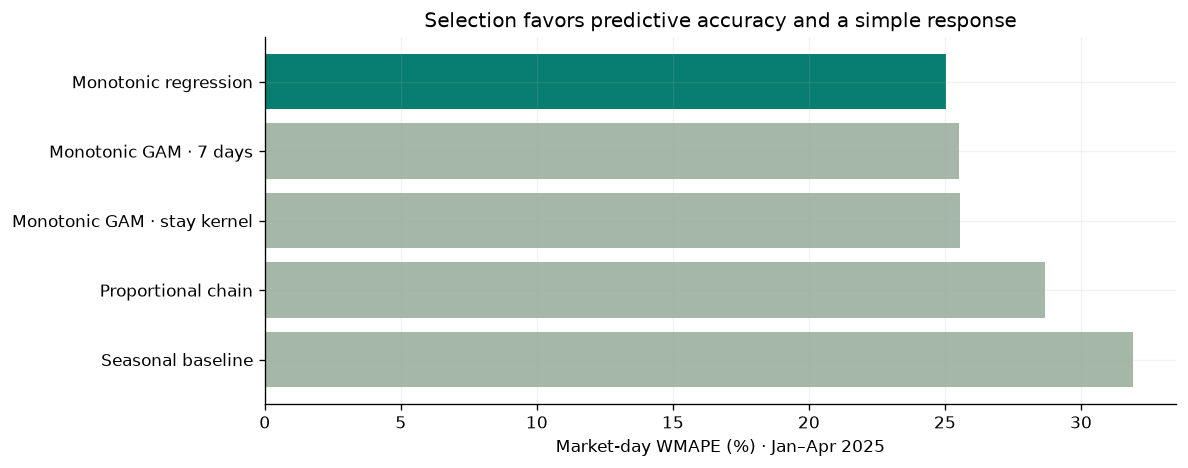

In [4]:
scores = result['scores'].copy()
display(scores.style.format({'wmape':'{:.2%}', 'bias':'{:+.2%}', 'aggregate_wmape':'{:.2%}', 'median_market_wmape':'{:.2%}', 'mae':'{:.1f}'}))
fig, ax = plt.subplots(figsize=(10,4))
colors = ['#087e70' if m == summary['selected'] else '#a5b7a7' for m in scores.model]
ax.barh(scores.model, scores.wmape*100, color=colors)
ax.invert_yaxis(); ax.set_xlabel('Market-day WMAPE (%) · Jan–Apr 2025'); ax.set_title('Selection favors predictive accuracy and a simple response')
plt.tight_layout(); plt.show()

,market,wmape,bias,observations
119,PAKISTAN,72.1%,+72.1%,120
107,ISRAEL,63.6%,+62.1%,120
134,UZBEKISTAN,59.8%,+54.1%,120
115,MOROCCO,56.4%,-55.3%,120
114,MEXICO,55.0%,+48.9%,120
122,QATAR,53.6%,-3.0%,120
127,SOUTH KOREA,50.7%,+46.6%,120
125,SAUDI ARABIA,49.4%,+13.7%,120
118,OMAN,44.7%,-18.6%,120
93,AZERBAIJAN,44.2%,-18.2%,120


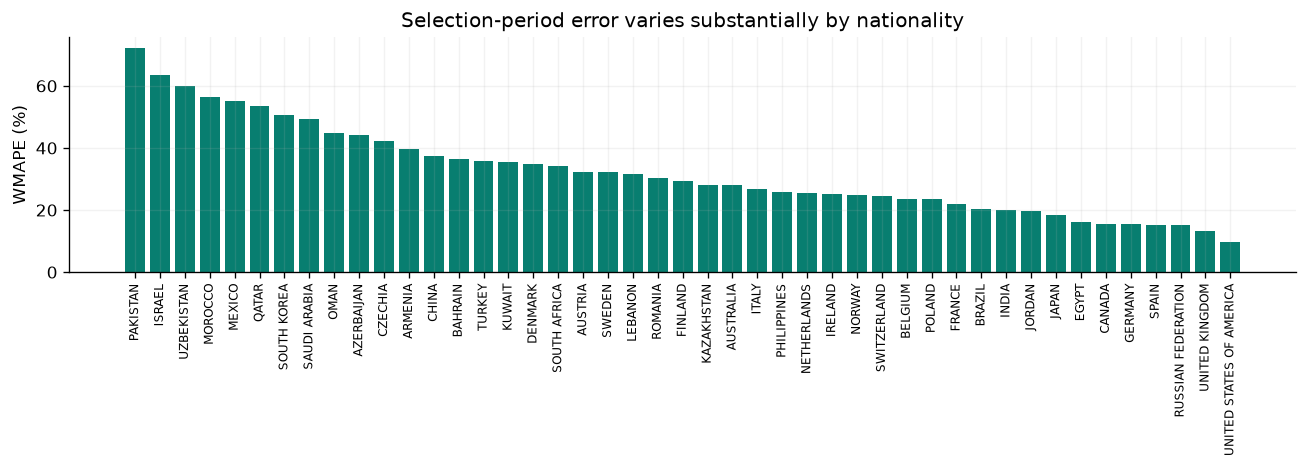

In [5]:
market_scores = pd.read_csv(OUT / 'selection_by_market.csv')
selected_markets = market_scores.loc[market_scores.model.eq(summary['selected'])].sort_values('wmape', ascending=False)
display(selected_markets[['market','wmape','bias','observations']].head(15).style.format({'wmape':'{:.1%}', 'bias':'{:+.1%}'}))
fig, ax = plt.subplots(figsize=(11,4))
ax.bar(selected_markets.market, selected_markets.wmape*100, color='#087e70'); ax.tick_params(axis='x',labelrotation=90,labelsize=7)
ax.set_ylabel('WMAPE (%)'); ax.set_title('Selection-period error varies substantially by nationality'); plt.tight_layout(); plt.show()

## 4 · Untouched audit and uncertainty check

Model choice is now frozen. May's per-market log residuals supply descriptive daily error envelopes. They are not causal scenario intervals, and 31 calibration days do not justify assuming stable 80% coverage. We measure their actual June–July coverage before deciding how to display uncertainty.

,Jun–Jul 2025 audit
wmape,0.277177
bias,0.013185
mae,138.010436
aggregate_wmape,0.064638
median_market_wmape,0.253837
observations,2743.000000
daily_band_coverage,0.613926


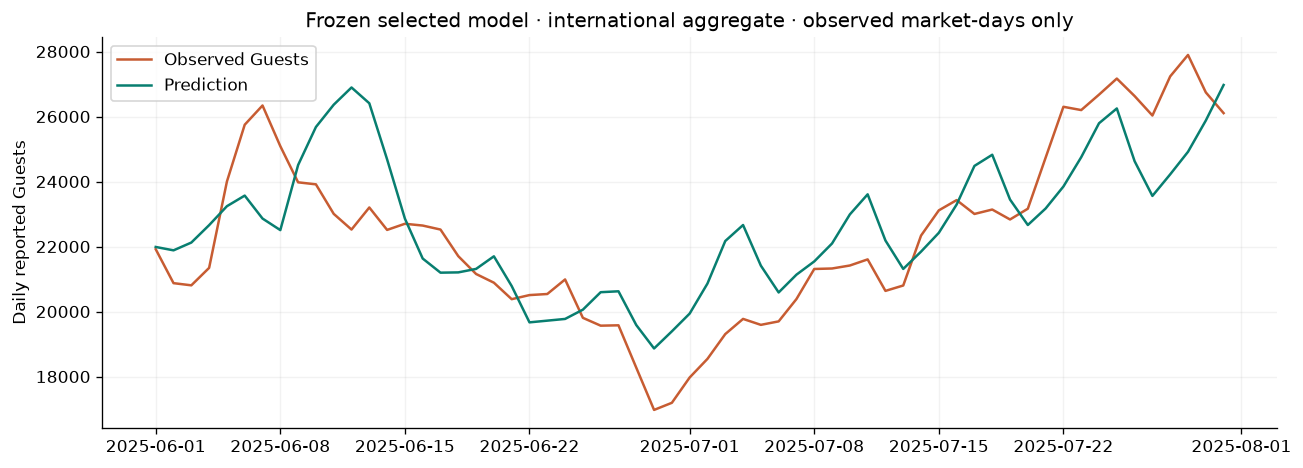

,daily_band_coverage
market,
AUSTRIA,6.6%
AZERBAIJAN,14.8%
OMAN,14.8%
UZBEKISTAN,18.0%
ISRAEL,19.7%
CZECHIA,21.3%
LEBANON,21.3%
UNITED KINGDOM,27.9%
FINLAND,31.1%


Empirical 10–90% band covered 61.4% of audit market-days.
The demo reports historical errors and extrapolation flags; it does not advertise a calibrated confidence interval.


In [6]:
display(pd.Series(summary['audit'], name='Jun–Jul 2025 audit').to_frame())
audit = result['chosen'].query("split == 'audit'").dropna(subset=['target'])
# Compare like-for-like observed market-days; missing targets excluded from both totals.
daily = audit.groupby('date')[['target','prediction']].sum()
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(daily.index,daily.target,label='Observed Guests',color='#c75c32'); ax.plot(daily.index,daily.prediction,label='Prediction',color='#087e70')
ax.set_title('Frozen selected model · international aggregate · observed market-days only'); ax.set_ylabel('Daily reported Guests'); ax.legend(); plt.tight_layout(); plt.show()
coverage = ((audit.target >= audit.lower) & (audit.target <= audit.upper)).groupby(audit.market).mean()
display(coverage.sort_values().rename('daily_band_coverage').to_frame().style.format('{:.1%}'))
print(f"Empirical 10–90% band covered {summary['audit']['daily_band_coverage']:.1%} of audit market-days.")
print('The demo reports historical errors and extrapolation flags; it does not advertise a calibrated confidence interval.')

## 5 · Read the model, not only the score

For the constrained regression, **Guests + 1 = calendar/trend factor × (1 + passenger exposure)^β**, including training smearing. β ≥ 0 is an elasticity in shifted variables. It is approximately the ordinary elasticity at large counts. An elasticity near zero means that the model found little additional aviation sensitivity after calendar and trend adjustment.

Below, calendar and time stay fixed at an actual audit day. Curves stay within each market's observed training exposure range. The GAM comparison remains available even if a simpler model wins.

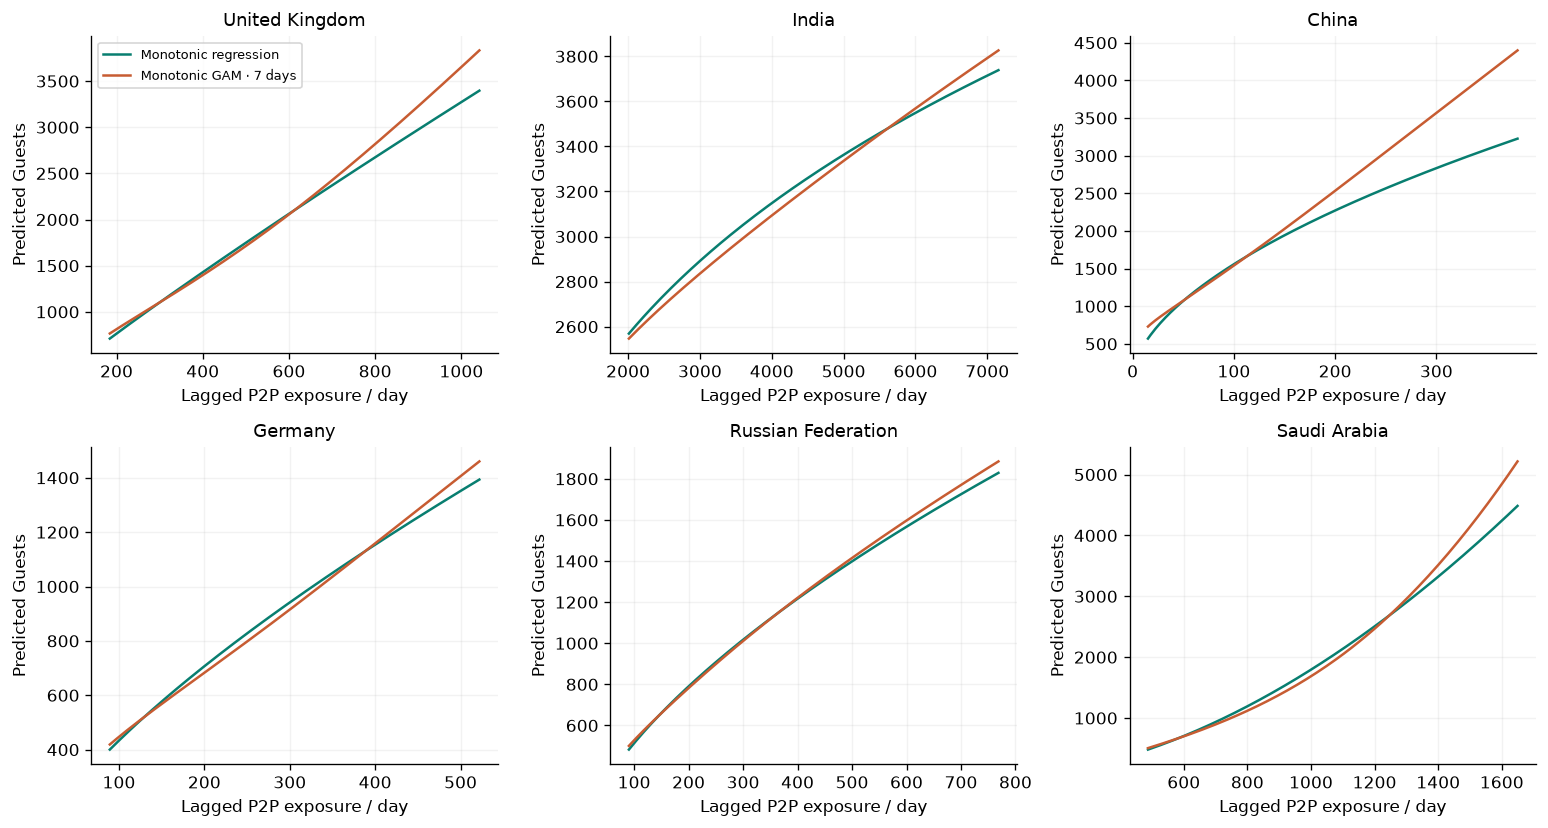

,market,beta,exposure_min,exposure_max
23,QATAR,1.866,258.7,1563.9
25,SAUDI ARABIA,1.831,487.4,1649.4
17,KUWAIT,1.264,96.7,746.6
3,BAHRAIN,1.125,153.0,670.6
0,ARMENIA,0.989,112.7,517.0
30,UNITED KINGDOM,0.906,184.4,1041.7
1,AUSTRIA,0.851,110.6,301.4
12,ISRAEL,0.764,8.3,509.0
13,ITALY,0.737,217.3,681.9
2,AZERBAIJAN,0.713,128.3,641.4


In [7]:
chosen_fits = result['fits'][summary['selected']]
markets = ['UNITED KINGDOM','INDIA','CHINA','GERMANY','RUSSIAN FEDERATION','SAUDI ARABIA']
fig, axes = plt.subplots(2,3,figsize=(13,7))
for ax, market in zip(axes.flat, markets):
    for name, color in [('Monotonic regression','#087e70'),('Monotonic GAM · 7 days','#c75c32')]:
        model = result['fits'][name][market]
        x = np.linspace(*model.train_range,150)
        d = panel.loc[panel.market.eq(market) & panel.date.eq('2025-07-15')].iloc[[0]]
        grid = pd.concat([d]*len(x),ignore_index=True); grid[model.feature] = x
        ax.plot(x,model.predict(grid),label=name,color=color)
    ax.set_title(market.title(),fontsize=11); ax.set_xlabel('Lagged P2P exposure / day'); ax.set_ylabel('Predicted Guests')
axes.flat[0].legend(fontsize=8); plt.tight_layout(); plt.show()
elasticities = pd.DataFrame([{'market':m,'beta':fit.coef[-1],'exposure_min':fit.train_range[0],'exposure_max':fit.train_range[1]} for m,fit in chosen_fits.items() if fit.kind == 'linear']).sort_values('beta',ascending=False)
if not elasticities.empty:
    display(elasticities.style.format({'beta':'{:.3f}','exposure_min':'{:.1f}','exposure_max':'{:.1f}'}))
    elasticities.to_csv(OUT / 'selected_elasticities.csv',index=False)

## 6 · Export the interactive scenario lab

1. Monthly average weekly frequency × month length / 7 × seats per flight gives seats.
2. Seats × occupied-seat load × observed infant adjustment gives total passenger counts.
3. Remove transfer/transit share to obtain P2P passengers.
4. Scale the observed within-month daily P2P profile, retaining the preceding 27 days unchanged.
5. Recompute the lagged exposure and apply the selected learned response with calendar effects held fixed.

The selected regression exports its exact coefficient; GAM exports a dense response table if selected on a future rebuild. JavaScript predictions are checked against Python. No synthetic forecast values are embedded.

This is an **existing-market** simulator. Adding a new origin or estimating occupancy requires additional assumptions/data; the interface does not fabricate either. Flight closures are shown as extrapolation where appropriate, and non-aviation residual demand can remain.

In [8]:
payload = export_demo(result)
print('Standalone HTML:', ROOT / 'demo/index.html')
print('Markets:', len(payload['markets']), '| Months:', len(payload['months']))
print('No server, external JavaScript, fonts or network requests are required.')

Standalone HTML: /home/srijan/Desktop/hack/ATRC_challenge/demo/index.html
Markets: 45 | Months: 14
No server, external JavaScript, fonts or network requests are required.


## 7 · Integration verification

Checks cover unfilled audit targets, split boundaries, shape constraints for every candidate, baseline arithmetic, Python/export prediction parity, nonnegative forecasts, scenario timing, monotonic slider sweeps, invalid inputs and the invariance of unsupported markets. The browser arithmetic is executed with Node; no model is reimplemented by hand for the demo.

In [9]:
verification = verify(result,payload)
display(verification)
display(json.loads((OUT / 'verification.json').read_text()))

{"assertions":214722,"max_absolute_parity_error":3.001332515850663e-11,"passed":true}

Passed 7,398 Python integration checks.


{'checks': 7398, 'passed': True}

{'python_checks': 7398,
 'node': {'assertions': 214722,
  'max_absolute_parity_error': 3.001332515850663e-11,
  'passed': True},
 'passed': True}

## 8 · Findings and next experiment

Read the results below before proposing extra complexity. This experiment assesses one temporal split; calendar-month effects can miss moving holidays and linear trend can miss regime changes. The simple model's shape and speed are useful for a hackathon interface, while nationality-level error and the uncertain bridge remain material limits.

Useful next work: an organizer-confirmed bridge and target definition; a verified moving-event calendar; then rolling temporal folds within pre-audit data. Any future tuning informed by this audit needs a new untouched evaluation period.

In [10]:
best = scores.loc[scores.model.eq(summary['selected'])].iloc[0]
seasonal = scores.loc[scores.model.eq('Seasonal baseline')].iloc[0]
print(f"Selected: {summary['selected']}.")
print(f"Selection market WMAPE: {best.wmape:.1%}, seasonal baseline: {seasonal.wmape:.1%}.")
print(f"Relative error reduction: {1-best.wmape/seasonal.wmape:.1%}.")
print(f"Audit market WMAPE: {summary['audit']['wmape']:.1%}; aggregate: {summary['audit']['aggregate_wmape']:.1%}.")
print('Slider responses are constrained and reproducible, but not causally identified.')
print('Open demo/index.html directly in a browser. Re-running this notebook rebuilds it.')

Selected: Monotonic regression.
Selection market WMAPE: 25.0%, seasonal baseline: 31.9%.
Relative error reduction: 21.5%.
Audit market WMAPE: 27.7%; aggregate: 6.5%.
Slider responses are constrained and reproducible, but not causally identified.
Open demo/index.html directly in a browser. Re-running this notebook rebuilds it.
